<a href="https://colab.research.google.com/github/santhwana27/Machine-Learning-Lab-Programs/blob/main/knn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving KNN_Dataset.xlsx to KNN_Dataset.xlsx

TASK 1: LOAD AND UNDERSTAND THE DATASET

First 10 Records:
Phone_ID  RAM_GB  Storage_GB  Battery_mAh  Camera_MP  Category
     P01       4          41         4763         63    Budget
     P02       4          49         4928         48    Budget
     P03       7         119         4786         62 Mid-Range
     P04      13         261         4656        123   Premium
     P05       3          57         4335         41    Budget
     P06      13         285         4746         98   Premium
     P07       9         123         4485         50 Mid-Range
     P08      12         288         4413         95   Premium
     P09       5          65         4601         59    Budget
     P10      11         250         4288        100   Premium

Input Features:
['Phone_ID', 'RAM_GB', 'Storage_GB', 'Battery_mAh', 'Camera_MP']

Target Variable:
Category

Category Distribution:
Category
Budget       20
Mid-Range    20
Premium      20


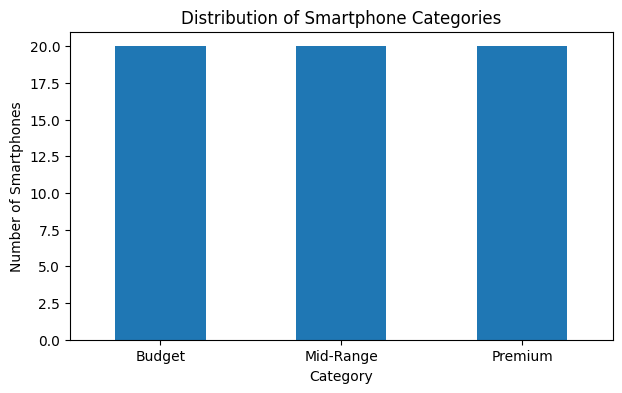


Numerical Features Used for KNN:
['RAM_GB', 'Storage_GB', 'Battery_mAh', 'Camera_MP']

TASK 2: DISTANCE CALCULATION AND NEAREST NEIGHBORS

New Smartphone Record:
RAM_GB           8.05
Storage_GB     152.19
Battery_mAh   4815.38
Camera_MP       75.36

Distances Before Scaling:
 RAM_GB  Storage_GB  Battery_mAh  Camera_MP  Category  Distance
      7         139         4836         64 Mid-Range   27.0040
      8         150         4825         47 Mid-Range   30.0242
      8         157         4875         74 Mid-Range   59.8281
      7         108         4864         45 Mid-Range   72.3828
      4          69         4805         53    Budget   86.8599
     13         247         4798        106   Premium  101.2643
      4          45         4808         61    Budget  108.4748
      4          43         4807         49    Budget  112.7115
      4          41         4763         63    Budget  123.5968
     14         260         4758        112   Premium  127.6464
      4          6

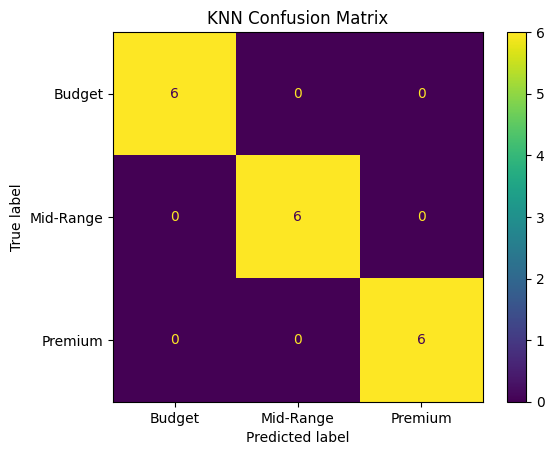


Multiclass TP, TN, FP and FN:
TP: Records of a class correctly predicted as that class.
TN: Records belonging to other classes correctly predicted as not belonging to that class.
FP: Records from other classes incorrectly predicted as a particular class.
FN: Records belonging to a class incorrectly predicted as another class.

TASK 5: SELECTING THE VALUE OF K

K Value vs Testing Accuracy:
 K  Testing Accuracy
 1            1.0000
 2            1.0000
 3            1.0000
 4            1.0000
 5            1.0000
 6            1.0000
 7            1.0000
 8            1.0000
 9            1.0000
10            1.0000
11            1.0000
12            1.0000
13            1.0000
14            1.0000
15            1.0000

Suitable K based on Testing Accuracy:
1

Testing Accuracy for Selected K:
1.0000


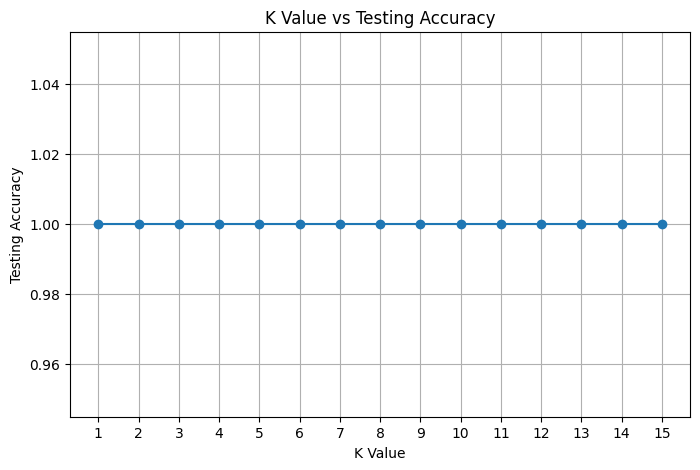


Small K vs Large K:
Model  Testing Accuracy
K = 1            1.0000
K = 9            1.0000

A small K considers fewer nearby records and can be more sensitive to individual observations.
A larger K considers more neighboring records and generally produces smoother majority voting.

TASK 6: NEW PREDICTION AND MODEL UNDERSTANDING

Three New Smartphone Records:
 RAM_GB  Storage_GB  Battery_mAh  Camera_MP
   7.87      148.95      4786.98      73.27
   3.00       35.00      4054.00      34.00
  14.00      292.00      5699.00     134.00

Predictions and Class Probabilities:
 RAM_GB  Storage_GB  Battery_mAh  Camera_MP Predicted Category  P(Budget)  P(Mid-Range)  P(Premium)
 7.8700    148.9500    4786.9800    73.2700          Mid-Range     0.0000        1.0000      0.0000
 3.0000     35.0000    4054.0000    34.0000             Budget     1.0000        0.0000      0.0000
14.0000    292.0000    5699.0000   134.0000            Premium     0.0000        0.0000      1.0000

Nearest Neighbors for 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# TASK 1: LOAD AND UNDERSTAND THE DATASET

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_excel(file_name)

target = "Category"

print("\n" + "=" * 70)
print("TASK 1: LOAD AND UNDERSTAND THE DATASET")
print("=" * 70)

print("\nFirst 10 Records:")
print(df.head(10).to_string(index=False))

features = [
    col for col in df.columns
    if col != target
]

print("\nInput Features:")
print(features)

print("\nTarget Variable:")
print(target)

print("\nCategory Distribution:")
print(df[target].value_counts().to_string())

plt.figure(figsize=(7, 4))

df[target].value_counts().plot(
    kind="bar"
)

plt.xlabel("Category")
plt.ylabel("Number of Smartphones")
plt.title("Distribution of Smartphone Categories")
plt.xticks(rotation=0)

plt.show()

numerical_features = df[features].select_dtypes(
    include=np.number
).columns.tolist()

print("\nNumerical Features Used for KNN:")
print(numerical_features)


# TASK 2: DISTANCE CALCULATION AND NEAREST NEIGHBORS

print("\n" + "=" * 70)
print("TASK 2: DISTANCE CALCULATION AND NEAREST NEIGHBORS")
print("=" * 70)

X = df[numerical_features]
y = df[target]

X_train_manual, X_test_manual, y_train_manual, y_test_manual = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

new_smartphone = X_train_manual.mean()

print("\nNew Smartphone Record:")
print(
    new_smartphone.to_string(
        float_format=lambda x: f"{x:.2f}"
    )
)

manual_distances = np.sqrt(
    np.sum(
        (
            X_train_manual.values
            -
            new_smartphone.values
        ) ** 2,
        axis=1
    )
)

distance_table = X_train_manual.copy()

distance_table["Category"] = y_train_manual.values

distance_table["Distance"] = manual_distances

distance_table = distance_table.sort_values(
    by="Distance"
)

print("\nDistances Before Scaling:")

print(
    distance_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

K = 5

nearest_neighbors = distance_table.head(K)

print(
    f"\nNearest {K} Neighbors:"
)

print(
    nearest_neighbors.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

majority_class = (
    nearest_neighbors["Category"]
    .value_counts()
    .idxmax()
)

print("\nMajority Class:")
print(majority_class)

print(
    "\nPrediction using Majority Voting:"
)

print(majority_class)


# TASK 3: FEATURE SCALING AND KNN WORKING

print("\n" + "=" * 70)
print("TASK 3: FEATURE SCALING AND KNN WORKING")
print("=" * 70)

print("\nWhy Feature Scaling is Required:")

print(
    "KNN uses distance to find neighboring records. "
    "If features have different ranges, a feature with "
    "larger values can dominate the distance calculation."
)

print(
    "StandardScaler converts the features to a common scale "
    "with approximately mean 0 and standard deviation 1."
)

scaler_manual = StandardScaler()

X_train_scaled_manual = scaler_manual.fit_transform(
    X_train_manual
)

new_smartphone_scaled = scaler_manual.transform(
    new_smartphone.to_frame().T
)[0]

scaled_distances = np.sqrt(
    np.sum(
        (
            X_train_scaled_manual
            -
            new_smartphone_scaled
        ) ** 2,
        axis=1
    )
)

scaled_distance_table = X_train_manual.copy()

scaled_distance_table["Category"] = (
    y_train_manual.values
)

scaled_distance_table["Scaled Distance"] = (
    scaled_distances
)

scaled_distance_table = (
    scaled_distance_table
    .sort_values(
        by="Scaled Distance"
    )
)

print("\nDistances After Scaling:")

print(
    scaled_distance_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

scaled_neighbors = (
    scaled_distance_table
    .head(K)
)

print(
    f"\nNearest {K} Neighbors After Scaling:"
)

print(
    scaled_neighbors.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

scaled_majority_class = (
    scaled_neighbors["Category"]
    .value_counts()
    .idxmax()
)

print("\nMajority Class After Scaling:")
print(scaled_majority_class)

print("\nComplete KNN Working:")

print(
    "Input → Feature Scaling → Distance Calculation "
    "→ Sort by Distance → Select K Neighbors "
    "→ Majority Voting → Prediction"
)


# TASK 4: IMPLEMENT KNN USING SCIKIT-LEARN

print("\n" + "=" * 70)
print("TASK 4: IMPLEMENT KNN USING SCIKIT-LEARN")
print("=" * 70)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

knn_model = KNeighborsClassifier(
    n_neighbors=K
)

knn_model.fit(
    X_train_scaled,
    y_train
)

knn_predictions = knn_model.predict(
    X_test_scaled
)

accuracy = accuracy_score(
    y_test,
    knn_predictions
)

precision = precision_score(
    y_test,
    knn_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    knn_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    knn_predictions,
    average="weighted",
    zero_division=0
)

evaluation_table = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

print("\nKNN Evaluation:")

print(
    evaluation_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

cm = confusion_matrix(
    y_test,
    knn_predictions,
    labels=knn_model.classes_
)

print("\nConfusion Matrix:")

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=knn_model.classes_
)

disp.plot()

plt.title(
    "KNN Confusion Matrix"
)

plt.show()

print("\nMulticlass TP, TN, FP and FN:")

print(
    "TP: Records of a class correctly predicted "
    "as that class."
)

print(
    "TN: Records belonging to other classes correctly "
    "predicted as not belonging to that class."
)

print(
    "FP: Records from other classes incorrectly "
    "predicted as a particular class."
)

print(
    "FN: Records belonging to a class incorrectly "
    "predicted as another class."
)


# TASK 5: SELECTING THE VALUE OF K

print("\n" + "=" * 70)
print("TASK 5: SELECTING THE VALUE OF K")
print("=" * 70)

max_k = min(
    15,
    len(X_train)
)

k_values = list(
    range(
        1,
        max_k + 1
    )
)

k_accuracies = []

for k in k_values:

    model = KNeighborsClassifier(
        n_neighbors=k
    )

    model.fit(
        X_train_scaled,
        y_train
    )

    predictions = model.predict(
        X_test_scaled
    )

    k_accuracies.append(
        accuracy_score(
            y_test,
            predictions
        )
    )

k_table = pd.DataFrame({
    "K": k_values,
    "Testing Accuracy": k_accuracies
})

print("\nK Value vs Testing Accuracy:")

print(
    k_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

best_k_index = np.argmax(
    k_accuracies
)

best_k = k_values[
    best_k_index
]

best_k_accuracy = k_accuracies[
    best_k_index
]

print("\nSuitable K based on Testing Accuracy:")
print(best_k)

print("\nTesting Accuracy for Selected K:")
print(f"{best_k_accuracy:.4f}")

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    k_accuracies,
    marker="o"
)

plt.xlabel("K Value")
plt.ylabel("Testing Accuracy")
plt.title("K Value vs Testing Accuracy")

plt.xticks(k_values)

plt.grid(True)

plt.show()

small_k = 1

large_k = max(
    3,
    min(
        9,
        len(X_train)
    )
)

small_k_model = KNeighborsClassifier(
    n_neighbors=small_k
)

large_k_model = KNeighborsClassifier(
    n_neighbors=large_k
)

small_k_model.fit(
    X_train_scaled,
    y_train
)

large_k_model.fit(
    X_train_scaled,
    y_train
)

small_k_predictions = (
    small_k_model.predict(
        X_test_scaled
    )
)

large_k_predictions = (
    large_k_model.predict(
        X_test_scaled
    )
)

print("\nSmall K vs Large K:")

comparison_k = pd.DataFrame({
    "Model": [
        f"K = {small_k}",
        f"K = {large_k}"
    ],
    "Testing Accuracy": [
        accuracy_score(
            y_test,
            small_k_predictions
        ),
        accuracy_score(
            y_test,
            large_k_predictions
        )
    ]
})

print(
    comparison_k.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print(
    "\nA small K considers fewer nearby records and "
    "can be more sensitive to individual observations."
)

print(
    "A larger K considers more neighboring records and "
    "generally produces smoother majority voting."
)


# TASK 6: NEW PREDICTION AND MODEL UNDERSTANDING

print("\n" + "=" * 70)
print("TASK 6: NEW PREDICTION AND MODEL UNDERSTANDING")
print("=" * 70)

new_students = pd.DataFrame()

for feature in numerical_features:

    minimum = df[feature].min()
    maximum = df[feature].max()
    mean_value = df[feature].mean()

    new_students[feature] = [
        round(mean_value, 2),
        round(minimum, 2),
        round(maximum, 2)
    ]

new_students = new_students[
    numerical_features
]

new_students_scaled = scaler.transform(
    new_students
)

new_predictions = knn_model.predict(
    new_students_scaled
)

new_probabilities = (
    knn_model.predict_proba(
        new_students_scaled
    )
)

prediction_table = new_students.copy()

prediction_table[
    "Predicted Category"
] = new_predictions

for i, category in enumerate(
    knn_model.classes_
):

    prediction_table[
        f"P({category})"
    ] = new_probabilities[:, i]

print("\nThree New Smartphone Records:")

print(
    new_students.to_string(
        index=False
    )
)

print("\nPredictions and Class Probabilities:")

print(
    prediction_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


print("\nNearest Neighbors for Each New Smartphone:")

for i in range(
    len(new_students)
):

    distances = np.sqrt(
        np.sum(
            (
                X_train_scaled
                -
                new_students_scaled[i]
            ) ** 2,
            axis=1
        )
    )

    neighbor_indices = np.argsort(
        distances
    )[:K]

    neighbor_table = X_train.iloc[
        neighbor_indices
    ].copy()

    neighbor_table[
        "Category"
    ] = y_train.iloc[
        neighbor_indices
    ].values

    neighbor_table[
        "Distance"
    ] = distances[
        neighbor_indices
    ]

    print(
        f"\nNew Smartphone {i + 1}:"
    )

    print(
        neighbor_table.to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}"
        )
    )

    print(
        "Predicted Category:",
        new_predictions[i]
    )

print("\nEffect of K and Distance:")

print(
    "K determines how many neighboring records are "
    "considered for the prediction."
)

print(
    "Smaller K gives more importance to very close "
    "records and can be sensitive to noise."
)

print(
    "Larger K considers more records and uses broader "
    "majority voting."
)

print(
    "Records with smaller distance are more similar "
    "to the new smartphone and have greater influence "
    "on the KNN prediction."
)